# Imputing missing values with variants of IterativeImputer

This comparison follows [the scikit-learn gallery example](https://scikit-learn.org/stable/auto_examples/impute/plot_iterative_imputer_variants_comparison.html)
at revision `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.
It uses every tenth row of California housing, one seeded missing feature per
row, and five unshuffled folds. Each fold fits its own robust scaler, imputer
and Bayesian ridge predictor. The complete-data baseline skips imputation.

The initial run downloads the California housing dataset to this notebook's
private build directory.

The gallery example is by the scikit-learn developers and uses the BSD-3-Clause license.

In [1]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import sklearn

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("impute/plot_iterative_imputer_variants_comparison")

revision = "4358542a1bd39af2e7e1cbace8b9fed067473c5b"
sk_source = ROOT.parent / "scikit-learn"
sk_installed = Path(sklearn.__file__).parent
for module in (
    "datasets/_california_housing.py", "preprocessing/_data.py",
    "impute/_base.py", "impute/_iterative.py", "linear_model/_bayes.py",
    "ensemble/_forest.py", "kernel_approximation.py", "linear_model/_ridge.py",
    "neighbors/_regression.py", "model_selection/_split.py",
    "model_selection/_validation.py", "pipeline.py",
    "tree/_criterion.pyx", "tree/_partitioner.pyx",
    "tree/_splitter.pyx", "tree/_tree.pyx",
):
    source = subprocess.check_output(
        ["git", "-C", sk_source, "show", f"{revision}:sklearn/{module}"]
    )
    assert (sk_installed / module).read_bytes() == source, (
        f"Install scikit-learn built from {revision} to run this notebook. "
        f"Source mismatch in {module}."
    )

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

X, y = fetch_california_housing(data_home=nb.dir / "data", return_X_y=True)
X, y = X[::10], y[::10]
X_missing = X.copy()
rng = np.random.RandomState(0)
X_missing[np.arange(len(X)), rng.choice(X.shape[1], len(X))] = np.nan
nb.share(X=X, X_missing=X_missing, y=y)

variants = {
    "bayesian_ridge": (BayesianRidge(), 1e-3),
    "forest": (
        RandomForestRegressor(n_estimators=5, max_depth=10, bootstrap=True,
                              max_samples=0.5, n_jobs=2, random_state=0),
        1e-1,
    ),
    "nystroem_ridge": (
        make_pipeline(Nystroem(kernel="polynomial", degree=2, random_state=0),
                      Ridge(alpha=1e4)),
        1e-1,
    ),
    "knn": (KNeighborsRegressor(n_neighbors=10), 1e-2),
}

def fold_scores(data, *imputers):
    pipeline = make_pipeline(RobustScaler(), *imputers, BayesianRidge())
    return cross_val_score(pipeline, data, y, scoring="neg_mean_squared_error",
                           cv=5, error_score="raise")

reference = {"full": fold_scores(X)}
for strategy in ("mean", "median"):
    reference[strategy] = fold_scores(X_missing, SimpleImputer(strategy=strategy))
for name, (estimator, tol) in variants.items():
    reference[name] = fold_scores(
        X_missing,
        IterativeImputer(estimator=estimator, random_state=0, max_iter=40, tol=tol),
    )

Moxie's `make_pipeline` takes two steps, so the imputer and final predictor
form a nested pipeline. The iterative imputer takes the regressor type as a
compile-time parameter. Float64 inputs match the gallery data, including for
the forest whose trees use Float32 internally. Mojo 1.0 needs the explicit
adapter type when calling `cross_val_score`.

In [3]:
%%mojo baselines
from numojo import NDArray

from moxie.base import Predictor, SupervisedScorer
from moxie.impute import SimpleImputer
from moxie.linear_model import BayesianRidge
from moxie.model_selection import (
    DenseSupervisedAdapter, ErrorPolicy, NegMeanSquaredError, cross_val_score,
)
from moxie.pipeline import make_pipeline
from moxie.preprocessing import RobustScaler
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


@no_inline
def score[E: SupervisedScorer & Predictor & Deinitable](
    name: String, estimator: E, X: Dense, y: Dense,
) raises:
    comptime Adapter = DenseSupervisedAdapter[E, S=NegMeanSquaredError[E, Dense]]
    var scores = cross_val_score[Adapter](
        estimator, X, y, Adapter(n_splits=5), error_score=ErrorPolicy(True, 0),
    )
    save(name, scores)


def main() raises:
    var X = load("X_missing")
    var y = load("y")
    score("full", make_pipeline(RobustScaler(), BayesianRidge()), load("X"), y)
    for strategy in ["mean", "median"]:
        var pipeline = make_pipeline(
            RobustScaler(), make_pipeline(SimpleImputer(strategy=strategy), BayesianRidge()),
        )
        score(strategy, pipeline, X, y)

In [4]:
%%mojo bayesian_ridge
from numojo import NDArray

from moxie.base import Predictor, SupervisedScorer
from moxie.impute import IterativeImputer
from moxie.linear_model import BayesianRidge
from moxie.model_selection import (
    DenseSupervisedAdapter, ErrorPolicy, NegMeanSquaredError, cross_val_score,
)
from moxie.pipeline import make_pipeline
from moxie.preprocessing import RobustScaler
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


@no_inline
def score[E: SupervisedScorer & Predictor & Deinitable](
    name: String, estimator: E, X: Dense, y: Dense,
) raises:
    comptime Adapter = DenseSupervisedAdapter[E, S=NegMeanSquaredError[E, Dense]]
    var scores = cross_val_score[Adapter](
        estimator, X, y, Adapter(n_splits=5), error_score=ErrorPolicy(True, 0),
    )
    save(name, scores)


def main() raises:
    var regressor = BayesianRidge()
    var imputer = IterativeImputer[DType.float64, type_of(regressor)](
        regressor^, random_state=0, max_iter=40, tol=1e-3,
    )
    var pipeline = make_pipeline(RobustScaler(), make_pipeline(imputer^, BayesianRidge()))
    score("bayesian_ridge", pipeline, load("X_missing"), load("y"))

In [5]:
%%mojo forest
from numojo import NDArray

from moxie.base import Predictor, SupervisedScorer
from moxie.ensemble import RandomForestRegressor
from moxie.ensemble._sampling import MaxSamples
from moxie.impute import IterativeImputer
from moxie.linear_model import BayesianRidge
from moxie.model_selection import (
    DenseSupervisedAdapter, ErrorPolicy, NegMeanSquaredError, cross_val_score,
)
from moxie.pipeline import make_pipeline
from moxie.preprocessing import RobustScaler
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


@no_inline
def score[E: SupervisedScorer & Predictor & Deinitable](
    name: String, estimator: E, X: Dense, y: Dense,
) raises:
    comptime Adapter = DenseSupervisedAdapter[E, S=NegMeanSquaredError[E, Dense]]
    var scores = cross_val_score[Adapter](
        estimator, X, y, Adapter(n_splits=5), error_score=ErrorPolicy(True, 0),
    )
    save(name, scores)


def main() raises:
    var regressor = RandomForestRegressor[DType.float64](
        n_estimators=5, max_depth=10, bootstrap=True,
        max_samples=MaxSamples(0.5), n_jobs=2, random_state=0,
    )
    var imputer = IterativeImputer[DType.float64, type_of(regressor)](
        regressor^, random_state=0, max_iter=40, tol=1e-1,
    )
    var pipeline = make_pipeline(RobustScaler(), make_pipeline(imputer^, BayesianRidge()))
    score("forest", pipeline, load("X_missing"), load("y"))

In [6]:
%%mojo nystroem_ridge
from numojo import NDArray

from moxie.base import Predictor, SupervisedScorer
from moxie.impute import IterativeImputer
from moxie.kernel_approximation import Nystroem
from moxie.linear_model import Ridge
from moxie.linear_model import BayesianRidge
from moxie.model_selection import (
    DenseSupervisedAdapter, ErrorPolicy, NegMeanSquaredError, cross_val_score,
)
from moxie.pipeline import make_pipeline
from moxie.preprocessing import RobustScaler
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


@no_inline
def score[E: SupervisedScorer & Predictor & Deinitable](
    name: String, estimator: E, X: Dense, y: Dense,
) raises:
    comptime Adapter = DenseSupervisedAdapter[E, S=NegMeanSquaredError[E, Dense]]
    var scores = cross_val_score[Adapter](
        estimator, X, y, Adapter(n_splits=5), error_score=ErrorPolicy(True, 0),
    )
    save(name, scores)


def main() raises:
    var regressor = make_pipeline(
        Nystroem(kernel="polynomial", degree=2.0, random_state=0),
        Ridge(alpha=1e4),
    )
    var imputer = IterativeImputer[DType.float64, type_of(regressor)](
        regressor^, random_state=0, max_iter=40, tol=1e-1,
    )
    var pipeline = make_pipeline(RobustScaler(), make_pipeline(imputer^, BayesianRidge()))
    score("nystroem_ridge", pipeline, load("X_missing"), load("y"))

In [7]:
%%mojo knn
from numojo import NDArray

from moxie.base import Predictor, SupervisedScorer
from moxie.impute import IterativeImputer
from moxie.neighbors import KNeighborsRegressor
from moxie.linear_model import BayesianRidge
from moxie.model_selection import (
    DenseSupervisedAdapter, ErrorPolicy, NegMeanSquaredError, cross_val_score,
)
from moxie.pipeline import make_pipeline
from moxie.preprocessing import RobustScaler
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


@no_inline
def score[E: SupervisedScorer & Predictor & Deinitable](
    name: String, estimator: E, X: Dense, y: Dense,
) raises:
    comptime Adapter = DenseSupervisedAdapter[E, S=NegMeanSquaredError[E, Dense]]
    var scores = cross_val_score[Adapter](
        estimator, X, y, Adapter(n_splits=5), error_score=ErrorPolicy(True, 0),
    )
    save(name, scores)


def main() raises:
    var regressor = KNeighborsRegressor(n_neighbors=10)
    var imputer = IterativeImputer[DType.float64, type_of(regressor)](
        regressor^, random_state=0, max_iter=40, tol=1e-2,
    )
    var pipeline = make_pipeline(RobustScaler(), make_pipeline(imputer^, BayesianRidge()))
    score("knn", pipeline, load("X_missing"), load("y"))

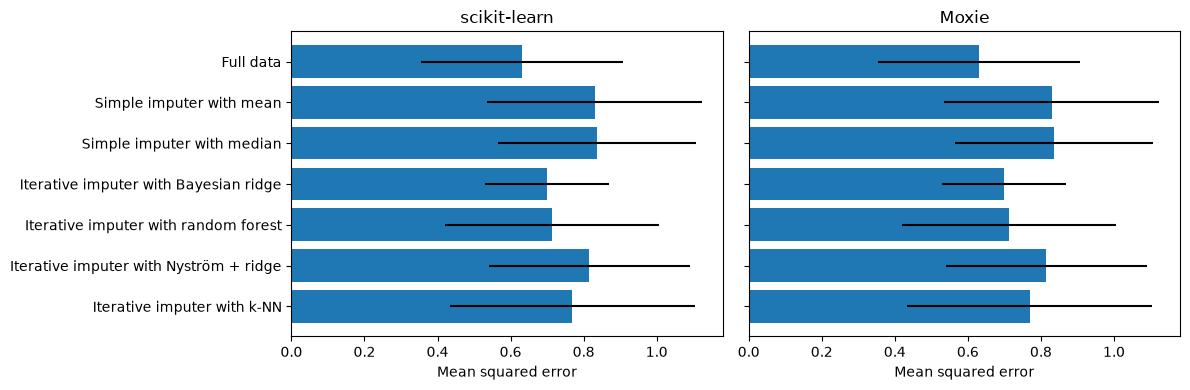

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Full data,PASS,"(5,)","(5,)",2.58e-12,2.38e-12,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order
Simple imputer with mean,PASS,"(5,)","(5,)",1.02e-12,7.66e-13,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order
Simple imputer with median,PASS,"(5,)","(5,)",3.99e-13,3.07e-13,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order
Iterative imputer with Bayesian ridge,PASS,"(5,)","(5,)",3.42e-13,3.64e-13,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order
Iterative imputer with random forest,PASS,"(5,)","(5,)",1.56e-13,2.04e-13,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order
Iterative imputer with Nyström + ridge,PASS,"(5,)","(5,)",6.11e-11,4.76e-11,"rtol=5e-09, atol=1e-10",,SVD roundoff amplified by the clipped polynomial kernel spectrum
Iterative imputer with k-NN,PASS,"(5,)","(5,)",4.64e-13,9.22e-13,"rtol=1e-09, atol=1e-10",,Float64 Bayesian ridge solver and reduction order


In [8]:
import matplotlib.pyplot as plt

native = {name: scores for group in nb.results.values() for name, scores in group.items()}
labels = {
    "full": "Full data",
    "mean": "Simple imputer with mean",
    "median": "Simple imputer with median",
    "bayesian_ridge": "Iterative imputer with Bayesian ridge",
    "forest": "Iterative imputer with random forest",
    "nystroem_ridge": "Iterative imputer with Nyström + ridge",
    "knn": "Iterative imputer with k-NN",
}
for name, label in labels.items():
    assert np.isfinite(reference[name]).all() and np.isfinite(native[name]).all()
    if name == "nystroem_ridge":
        rtol = 5e-9
        reason = "SVD roundoff amplified by the clipped polynomial kernel spectrum"
    else:
        rtol = 1e-9
        reason = "Float64 Bayesian ridge solver and reduction order"
    nb.compare(label, reference[name], native[name], rtol=rtol, atol=1e-10,
               reason=reason)

fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12, 4))
for ax, (title, scores) in zip(axes, (("scikit-learn", reference), ("Moxie", native))):
    ax.barh(list(labels.values()), [-scores[name].mean() for name in labels],
            xerr=[scores[name].std(ddof=1) for name in labels])
    ax.set_title(title)
    ax.set_xlabel("Mean squared error")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

nb.report()
nb.assert_parity()